In [1]:
# Cell 1 - Imports
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras.models import Model
from tensorflow.keras.layers import (Input, Conv1D, MaxPooling1D, LSTM, GRU, Dense,
                                      Dropout, BatchNormalization, Bidirectional,
                                      Concatenate, GlobalAveragePooling1D)
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau, ModelCheckpoint
from tensorflow.keras.optimizers import Adam
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
import pickle, json, os, warnings
warnings.filterwarnings('ignore')
tf.random.set_seed(42)
np.random.seed(42)
print("TensorFlow version:", tf.__version__)

TensorFlow version: 2.21.0


In [2]:
# Cell 2 - Configuration
SEQ_LENGTH    = 30
BATCH_SIZE    = 64
EPOCHS        = 100
LEARNING_RATE = 0.0005
MODEL_NAME    = 'hybrid_cnn_lstm_gru'
print(f"Config: SEQ_LENGTH={SEQ_LENGTH}, LR={LEARNING_RATE}, MODEL={MODEL_NAME}")

Config: SEQ_LENGTH=30, LR=0.0005, MODEL=hybrid_cnn_lstm_gru


In [3]:
# Cell 3 - Load Data
full_df = pd.read_csv('../data/processed/full_engineered.csv', parse_dates=['Date'])
with open('../data/processed/top_features.pkl', 'rb') as f:
    feature_cols = pickle.load(f)
with open('../data/processed/scaler_y.pkl', 'rb') as f:
    scaler_y = pickle.load(f)
target_col = 'Units_Sold_scaled'
print(f"Data loaded. Shape: {full_df.shape} | Features: {len(feature_cols)}")

Data loaded. Shape: (89750, 56) | Features: 30


In [4]:
# Cell 4 - Create Sequences & Splits
def create_sequences(data, feature_cols, target_col, seq_length=30):
    X_seqs, y_seqs = [], []
    for sku in sorted(data['SKU_ID'].unique()):
        sku_data = data[data['SKU_ID'] == sku].sort_values('Date')
        X = sku_data[feature_cols].fillna(0).values
        y = sku_data[target_col].values
        for i in range(seq_length, len(X)):
            X_seqs.append(X[i - seq_length:i])
            y_seqs.append(y[i])
    return np.array(X_seqs, dtype=np.float32), np.array(y_seqs, dtype=np.float32)

dates = np.sort(full_df['Date'].unique())
n = len(dates)
train_cutoff = dates[int(n * 0.70)]
val_cutoff   = dates[int(n * 0.85)]
train_df = full_df[full_df['Date'] <= train_cutoff]
val_df   = full_df[(full_df['Date'] > train_cutoff) & (full_df['Date'] <= val_cutoff)]
test_df  = full_df[full_df['Date'] > val_cutoff]
X_train, y_train = create_sequences(train_df, feature_cols, target_col, SEQ_LENGTH)
X_val,   y_val   = create_sequences(val_df,   feature_cols, target_col, SEQ_LENGTH)
X_test,  y_test  = create_sequences(test_df,  feature_cols, target_col, SEQ_LENGTH)
print(f"X_train: {X_train.shape} | X_val: {X_val.shape} | X_test: {X_test.shape}")

X_train: (61500, 30, 30) | X_val: (12000, 30, 30) | X_test: (11750, 30, 30)


In [5]:
# Cell 5 - Build CNN-LSTM-GRU Hybrid Architecture
def build_hybrid_model(seq_length, n_features):
    """
    Three-branch hybrid:
      Branch 1 : CNN  - local pattern extraction via Conv1D
      Branch 2 : BiLSTM - bidirectional long-range dependencies
      Branch 3 : GRU  - efficient sequential modelling
    All branches merged via GlobalAveragePooling + Concatenate.
    """
    inputs = Input(shape=(seq_length, n_features), name='input_layer')

    # ── Branch 1: CNN ──────────────────────────────────────────
    x1 = Conv1D(filters=64,  kernel_size=3, activation='relu', padding='same')(inputs)
    x1 = BatchNormalization()(x1)
    x1 = Conv1D(filters=128, kernel_size=3, activation='relu', padding='same')(x1)
    x1 = BatchNormalization()(x1)
    x1 = MaxPooling1D(pool_size=2)(x1)
    x1 = Dropout(0.2)(x1)
    x1 = GlobalAveragePooling1D(name='gap_cnn')(x1)

    # ── Branch 2: Bidirectional LSTM ───────────────────────────
    x2 = Bidirectional(LSTM(64, return_sequences=True))(inputs)
    x2 = BatchNormalization()(x2)
    x2 = Dropout(0.3)(x2)
    x2 = Bidirectional(LSTM(32, return_sequences=True))(x2)
    x2 = BatchNormalization()(x2)
    x2 = GlobalAveragePooling1D(name='gap_lstm')(x2)

    # ── Branch 3: GRU ──────────────────────────────────────────
    x3 = GRU(64, return_sequences=True)(inputs)
    x3 = BatchNormalization()(x3)
    x3 = Dropout(0.3)(x3)
    x3 = GRU(32, return_sequences=True)(x3)
    x3 = BatchNormalization()(x3)
    x3 = GlobalAveragePooling1D(name='gap_gru')(x3)

    # ── Merge & Dense Head ─────────────────────────────────────
    merged = Concatenate(name='merge')([x1, x2, x3])
    x = Dense(128, activation='relu')(merged)
    x = BatchNormalization()(x)
    x = Dropout(0.3)(x)
    x = Dense(64, activation='relu')(x)
    x = Dropout(0.2)(x)
    x = Dense(32, activation='relu')(x)
    output = Dense(1, name='output')(x)

    return Model(inputs=inputs, outputs=output, name='CNN_BiLSTM_GRU_Hybrid')

model = build_hybrid_model(SEQ_LENGTH, len(feature_cols))
model.compile(optimizer=Adam(learning_rate=LEARNING_RATE), loss='huber', metrics=['mae'])
model.summary()

Model: "CNN_BiLSTM_GRU_Hybrid"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                  ┃ Output Shape              ┃         Param # ┃ Connected to               ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)      │ (None, 30, 30)            │               0 │ -                          │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ conv1d (Conv1D)               │ (None, 30, 64)            │           5,824 │ input_layer[0][0]          │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ batch_normalization           │ (None, 30, 64)            │             256 │ conv1d[0][0]               │
│ (BatchNormalization)          │                           │                 │                            │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ bidirectional (Bidirectional) │ (None, 30, 128)           │          48,640 │ input_layer[0][0]          │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ gru (GRU)                     │ (None, 30, 64)            │          18,432 │ input_layer[0][0]          │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ conv1d_1 (Conv1D)             │ (None, 30, 128)           │          24,704 │ batch_normalization[0][0]  │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ batch_normalization_2         │ (None, 30, 128)           │             512 │ bidirectional[0][0]        │
│ (BatchNormalization)          │                           │                 │                            │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ batch_normalization_4         │ (None, 30, 64)            │             256 │ gru[0][0]                  │
│ (BatchNormalization)          │                           │                 │                            │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ batch_normalization_1         │ (None, 30, 128)           │             512 │ conv1d_1[0][0]             │
│ (BatchNormalization)          │                           │                 │                            │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ dropout_1 (Dropout)           │ (None, 30, 128)           │               0 │ batch_normalization_2[0][… │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ dropout_2 (Dropout)           │ (None, 30, 64)            │               0 │ batch_normalization_4[0][… │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ max_pooling1d (MaxPooling1D)  │ (None, 15, 128)           │               0 │ batch_normalization_1[0][… │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ bidirectional_1               │ (None, 30, 64)            │          41,216 │ dropout_1[0][0]            │
│ (Bidirectional)               │                           │                 │                            │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ gru_1 (GRU)                   │ (None, 30, 32)            │           9,408 │ dropout_2[0][0]            │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ dropout (Dropout)             │ (None, 15, 128)           │               

 Total params: 189,825 (741.50 KB)

 Trainable params: 188,609 (736.75 KB)

 Non-trainable params: 1,216 (4.75 KB)

In [6]:
# Cell 6 - Save Model Architecture Diagram
os.makedirs('../outputs/plots', exist_ok=True)
try:
    tf.keras.utils.plot_model(
        model,
        to_file='../outputs/plots/06_hybrid_model_architecture.png',
        show_shapes=True, show_layer_names=True, dpi=100, expand_nested=True
    )
    print("Architecture diagram saved to outputs/plots/")
except Exception as e:
    print(f"Could not save architecture diagram (pydot/graphviz needed): {e}")

You must install pydot (`pip install pydot`) for `plot_model` to work.
Architecture diagram saved to outputs/plots/


In [7]:
# Cell 7 - Train Hybrid Model
os.makedirs('../models', exist_ok=True)
callbacks = [
    EarlyStopping(monitor='val_loss', patience=20, restore_best_weights=True, verbose=1),
    ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=8, min_lr=1e-7, verbose=1),
    ModelCheckpoint(f'../models/{MODEL_NAME}.keras', monitor='val_loss', save_best_only=True, verbose=1)
]
history = model.fit(X_train, y_train, validation_data=(X_val, y_val),
                    epochs=EPOCHS, batch_size=BATCH_SIZE, callbacks=callbacks, verbose=1)
print(f"Training complete. Best val_loss: {min(history.history['val_loss']):.6f}")

Epoch 1/100
961/961 ━━━━━━━━━━━━━━━━━━━━ 0s 61ms/step - loss: 0.0254 - mae: 0.1676
Epoch 1: val_loss improved from None to 0.00926, saving model to ../models/hybrid_cnn_lstm_gru.keras

Epoch 1: finished saving model to ../models/hybrid_cnn_lstm_gru.keras
961/961 ━━━━━━━━━━━━━━━━━━━━ 77s 65ms/step - loss: 0.0254 - mae: 0.1676 - val_loss: 0.0093 - val_mae: 0.1086 - learning_rate: 5.0000e-04
Epoch 2/100
961/961 ━━━━━━━━━━━━━━━━━━━━ 0s 55ms/step - loss: 0.0107 - mae: 0.1159
Epoch 2: val_loss improved from 0.00926 to 0.00794, saving model to ../models/hybrid_cnn_lstm_gru.keras

Epoch 2: finished saving model to ../models/hybrid_cnn_lstm_gru.keras
961/961 ━━━━━━━━━━━━━━━━━━━━ 56s 59ms/step - loss: 0.0107 - mae: 0.1159 - val_loss: 0.0079 - val_mae: 0.1007 - learning_rate: 5.0000e-04
Epoch 3/100
961/961 ━━━━━━━━━━━━━━━━━━━━ 0s 60ms/step - loss: 0.0092 - mae: 0.1079
Epoch 3: val_loss did not improve from 0.00794
961/961 ━━━━━━━━━━━━━━━━━━━━ 61s 63ms/step - loss: 0.0092 - mae: 0.1079 - val_loss:

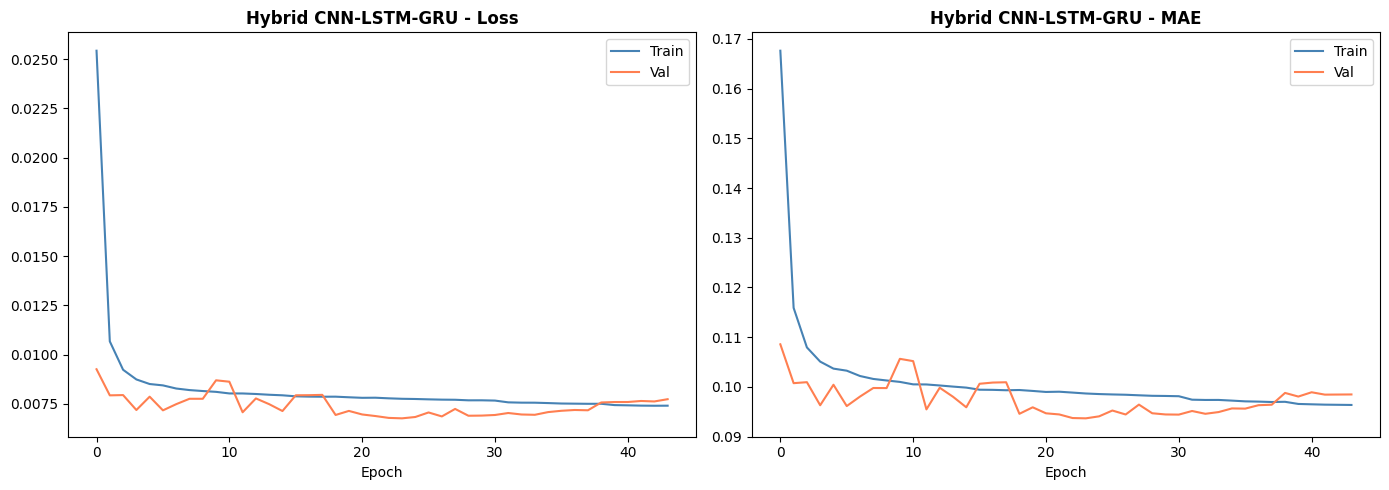

In [8]:
# Cell 8 - Training Curves
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].plot(history.history['loss'],     label='Train', color='steelblue')
axes[0].plot(history.history['val_loss'], label='Val',   color='coral')
axes[0].set_title('Hybrid CNN-LSTM-GRU - Loss', fontweight='bold')
axes[0].set_xlabel('Epoch'); axes[0].legend()
axes[1].plot(history.history['mae'],     label='Train', color='steelblue')
axes[1].plot(history.history['val_mae'], label='Val',   color='coral')
axes[1].set_title('Hybrid CNN-LSTM-GRU - MAE', fontweight='bold')
axes[1].set_xlabel('Epoch'); axes[1].legend()
plt.tight_layout()
plt.savefig('../outputs/plots/06_hybrid_training_curves.png', dpi=150, bbox_inches='tight')
plt.show()

In [9]:
# Cell 9 - Evaluate Hybrid Model
y_pred_scaled = model.predict(X_test, verbose=0).flatten()
y_pred = scaler_y.inverse_transform(y_pred_scaled.reshape(-1, 1)).flatten()
y_true = scaler_y.inverse_transform(y_test.reshape(-1, 1)).flatten()

rmse = np.sqrt(mean_squared_error(y_true, y_pred))
mae  = mean_absolute_error(y_true, y_pred)
r2   = r2_score(y_true, y_pred)
mape = np.mean(np.abs((y_true - y_pred) / (y_true + 1e-8))) * 100
print(f"HYBRID METRICS -> RMSE: {rmse:.4f} | MAE: {mae:.4f} | R²: {r2:.4f} | MAPE: {mape:.2f}%")

HYBRID METRICS -> RMSE: 6.4971 | MAE: 5.1651 | R²: -0.2795 | MAPE: 36.61%


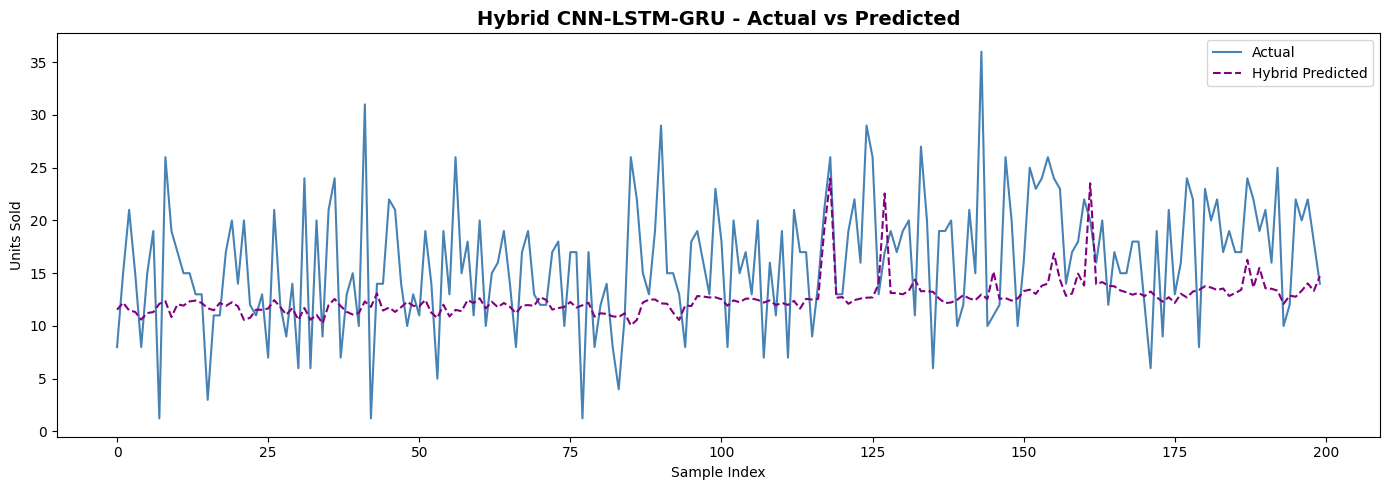

In [10]:
# Cell 10 - Actual vs Predicted Plot
fig, ax = plt.subplots(figsize=(14, 5))
ax.plot(y_true[:200], label='Actual',           color='steelblue', linewidth=1.5)
ax.plot(y_pred[:200], label='Hybrid Predicted', color='purple',    linewidth=1.5, linestyle='--')
ax.set_title('Hybrid CNN-LSTM-GRU - Actual vs Predicted', fontsize=14, fontweight='bold')
ax.set_xlabel('Sample Index'); ax.set_ylabel('Units Sold'); ax.legend()
plt.tight_layout()
plt.savefig('../outputs/plots/06_hybrid_actual_vs_predicted.png', dpi=150, bbox_inches='tight')
plt.show()

In [11]:
# Cell 11 - Save Hybrid Results
os.makedirs('../outputs/reports', exist_ok=True)
hybrid_results = {'RMSE': float(rmse), 'MAE': float(mae), 'R2': float(r2), 'MAPE': float(mape)}
with open('../outputs/reports/hybrid_metrics.json', 'w') as f:
    json.dump(hybrid_results, f, indent=2)
np.save('../data/processed/hybrid_predictions.npy', y_pred)
print("\n✅ Hybrid CNN-LSTM-GRU Model Complete!")
print("Model saved to: models/hybrid_cnn_lstm_gru.keras")


✅ Hybrid CNN-LSTM-GRU Model Complete!
Model saved to: models/hybrid_cnn_lstm_gru.keras
